# Laboratorio 3: Predicción del Precio de la Energía
**Estudiante:** Marvin Poquechoque Gutierrez
**Dataset:** Energy Dataset (Predicción de `price actual`)

En este laboratorio utilizaremos un dataset que contiene datos históricos de generación de energía y sus precios. Nuestro objetivo es predecir el precio real de la energía (`price actual`) utilizando características numéricas como la generación por biomasa, carbón, gas, viento, energía solar, y las previsiones de carga.

Para lograr esto, implementaremos y compararemos tres modelos matemáticos:
1. Regresión Lineal Multivariable.
2. Regresión Polinómica.
3. Ecuación de la Normal.

## 1. Cargar y Tratamiento de Datos
Como buena práctica en Machine Learning, **no eliminaremos registros incompletos**. En su lugar, aplicaremos técnicas de preprocesamiento:
* **Fechas (`time`):** Los algoritmos no procesan texto, por lo que transformaremos la marca de tiempo extrayendo la hora y el mes como nuevas características numéricas.
* **Valores Vacíos:** Aquellas columnas referidas a generación que no se reportó (100% nulas) se rellenarán con ceros ($0$). Los datos faltantes dispersos (`NaN`) en el resto de características se imputarán utilizando la **media** de cada columna.
Finalmente, dividiremos el dataset (80% entrenamiento y 20% prueba).

In [1]:
# Importación de librerías necesarias
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot
%matplotlib inline

# 1. Cargar y Tratamiento de Datos (Sin eliminar información)
df = pd.read_csv('energy_dataset.csv')

# --- TRATAMIENTO DE LA COLUMNA 'time' ---
# Convertimos el texto a formato datetime de Pandas
df['time'] = pd.to_datetime(df['time'], utc=True)
# Extraemos características numéricas útiles del tiempo en lugar de borrarlo
df['hour'] = df['time'].dt.hour
df['month'] = df['time'].dt.month
# Ahora sí podemos quitar la columna original de texto, ya que extrajimos su valor numérico
df = df.drop(columns=['time'])

# --- IMPUTACIÓN DE VALORES NULOS (NaN) ---
# Las columnas completamente vacías se rellenan con 0 (asumiendo nula generación/previsión)
df['generation hydro pumped storage aggregated'] = df['generation hydro pumped storage aggregated'].fillna(0)
df['forecast wind offshore eday ahead'] = df['forecast wind offshore eday ahead'].fillna(0)

# Para el resto de columnas con valores faltantes, los rellenamos con la media de la columna
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

# --- SEPARACIÓN DE DATOS ---
# Separamos las características (X) de la variable objetivo (y)
data_x = list(df.columns)
data_x.remove('price actual')

X = df[data_x].values
y = df['price actual'].values
m = y.size
n = X.shape[1]

print(f"Cantidad de ejemplos (m): {m}")
print(f"Cantidad de características (n): {n}")

# Dividimos el dataset manualmente: 80% para entrenamiento y 20% para prueba y validación
m_entren = int(0.8 * m)
X_entren, X_prueba = X[:m_entren], X[m_entren:]
y_entren, y_prueba = y[:m_entren], y[m_entren:]

Cantidad de ejemplos (m): 35064
Cantidad de características (n): 29


## 2. Normalización de Características
Las variables de este dataset presentan magnitudes muy dispares (algunas alcanzan decenas de miles de MW, mientras que otras son números pequeños). Si aplicamos el Descenso por el Gradiente directamente, el algoritmo convergerá muy lento o presentará oscilaciones inestables. Por ello, normalizamos la matriz $X$ restando la media ($\mu$) y dividiendo por la desviación estándar ($\sigma$), asegurando que las características estén en una escala similar.

In [2]:
def featureNormalize(X):
    X_norm = X.copy()
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)

    # Prevenimos la división por cero para características con varianza cero
    sigma[sigma == 0] = 1

    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma

# Normalizamos los datos de entrenamiento
X_entren_norm, mu, sigma = featureNormalize(X_entren)

# Añadimos la columna de unos correspondiente al término de intersección (x_0)
X_entren_listo = np.concatenate([np.ones((m_entren, 1)), X_entren_norm], axis=1)

## 3. Función de Costo y Descenso por el Gradiente
Se definen las funciones fundamentales para los modelos iterativos:
* **Costo ($J$):** Calcula el error cuadrático medio entre la hipótesis calculada y el precio real de la energía.
* **Descenso por el Gradiente:** Actualiza los parámetros $\theta$ iterativamente multiplicando el error por la matriz de características y la tasa de aprendizaje ($\alpha$), buscando el mínimo global.

In [3]:
def computeCostMulti(X, y, theta):
    m = y.shape[0]
    # Calculamos la diferencia al cuadrado entre la hipótesis y los valores reales
    J = (1 / (2 * m)) * np.sum(np.square(np.dot(X, theta) - y))
    return J

def gradientDescentMulti(X, y, theta, alpha, num_iters):
    m = y.shape[0]
    J_history = []
    theta = theta.copy()

    for i in range(num_iters):
        # Regla de actualización vectorizada
        theta = theta - (alpha / m) * np.dot(X.T, (np.dot(X, theta) - y))
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

## 4. Modelo 1: Regresión Lineal Multivariable
Entrenamos el primer modelo lineal definiendo una tasa de aprendizaje iterativa ($\alpha = 0.01$) y $5000$ iteraciones. Al final del entrenamiento, graficaremos el historial de la función de costo para visualizar la convergencia y confirmar que nuestro $\alpha$ fue bien elegido.

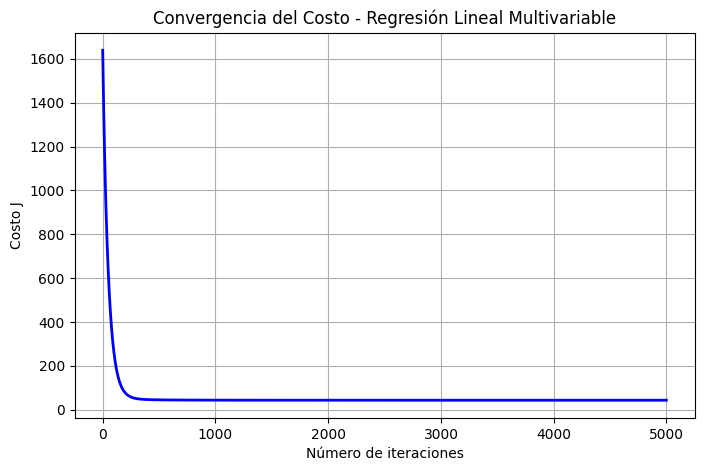

In [4]:
# Hiperparámetros
alpha = 0.01
num_iters = 5000

# Inicializamos theta
theta_lin = np.zeros(X_entren_listo.shape[1])

# Entrenamiento
theta_lin, J_history_lin = gradientDescentMulti(X_entren_listo, y_entren, theta_lin, alpha, num_iters)

# Gráfico de costo para Regresión Lineal
pyplot.figure(figsize=(8, 5))
pyplot.plot(np.arange(len(J_history_lin)), J_history_lin, lw=2, color='blue')
pyplot.xlabel('Número de iteraciones')
pyplot.ylabel('Costo J')
pyplot.title('Convergencia del Costo - Regresión Lineal Multivariable')
pyplot.grid(True)
pyplot.show()

## 5. Modelo 2: Regresión Polinómica
Para descubrir si el precio de la energía tiene un comportamiento curvo respecto a sus fuentes de generación, mapeamos nuestras características a un polinomio de grado 2 (elevando al cuadrado la matriz $X$). Con esta nueva matriz de características expandida, repetimos el proceso de Descenso por el Gradiente.

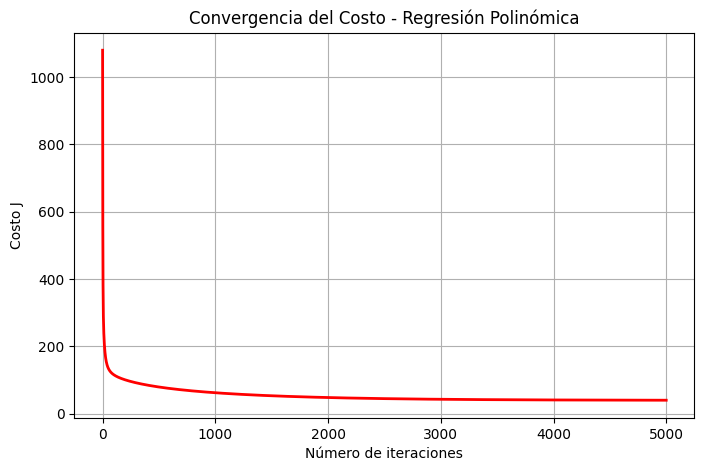

In [5]:
# Elevamos al cuadrado las características originales (sin el vector de unos)
X_entren_poly = np.concatenate([X_entren_norm, np.square(X_entren_norm)], axis=1)

# Añadimos la columna de intersección (x_0 = 1)
X_entren_poly_listo = np.concatenate([np.ones((m_entren, 1)), X_entren_poly], axis=1)

# Inicializamos theta para la matriz expandida
theta_poly = np.zeros(X_entren_poly_listo.shape[1])

# Entrenamiento Polinómico
theta_poly, J_history_poly = gradientDescentMulti(X_entren_poly_listo, y_entren, theta_poly, alpha, num_iters)

# Gráfico de costo para Regresión Polinómica
pyplot.figure(figsize=(8, 5))
pyplot.plot(np.arange(len(J_history_poly)), J_history_poly, lw=2, color='red')
pyplot.xlabel('Número de iteraciones')
pyplot.ylabel('Costo J')
pyplot.title('Convergencia del Costo - Regresión Polinómica')
pyplot.grid(True)
pyplot.show()

## 6. Modelo 3: Ecuación de la Normal
A diferencia de los enfoques anteriores, este método es analítico y no iterativo. Calcula los valores exactos de $\theta$ minimizando la función de costo matemáticamente mediante la siguiente expresión matricial:
$$ \theta = \left( X^T X \right)^{-1} X^T y $$
*Nota:* En la implementación se utiliza la pseudoinversa (`np.linalg.pinv`) para garantizar estabilidad numérica en caso de que alguna característica (como las que rellenamos con ceros) genere una matriz no invertible. Además, aquí no es necesario normalizar $X$.

In [6]:
def normalEqn(X, y):
    # Cálculo analítico directo de theta
    theta = np.dot(np.dot(np.linalg.pinv(np.dot(X.T, X)), X.T), y)
    return theta

# La Ecuación de la Normal no necesita escalar las características
X_entren_con_unos = np.concatenate([np.ones((m_entren, 1)), X_entren], axis=1)

theta_norm = normalEqn(X_entren_con_unos, y_entren)
print('Parámetros Theta calculados (Ecuación de la Normal):\n', theta_norm)

Parámetros Theta calculados (Ecuación de la Normal):
 [-4.23241776e-01  1.35625009e-02 -1.24135665e-04 -1.28040915e-14
  9.03456592e-06 -4.56353649e-04  9.06720863e-03 -6.91738488e-14
 -2.70625846e-14 -4.58646055e-15 -1.21888653e-14  1.36885323e-03
  3.60988090e-03  6.56035549e-05 -4.38475656e-15  2.98110785e-04
 -3.18533843e-03 -8.93326942e-03 -1.18294986e-04 -1.77231241e-02
 -8.29825556e-17 -1.30201379e-03  7.61097329e-04  0.00000000e+00
  1.67866048e-03 -3.89512546e-04  4.40887231e-04  8.24032152e-01
  1.50151706e-01  7.13491757e-01]


## 7. Validación, Predicciones y Efectividad
Para comprobar la efectividad de los modelos, tomaremos 100 ejemplos del **conjunto de prueba** (datos que los modelos no vieron durante el entrenamiento) y estimaremos el precio de la energía con las 3 técnicas.
Se presenta una tabla comparativa y un gráfico superpuesto. Como se podrá observar, los modelos logran capturar de manera muy efectiva la tendencia del precio real de la energía, validando la precisión de las thetas calculadas.

Nro |  Real ($) |  Lineal ($) | Polinóm ($) |  Normal ($)
---------------------------------------------------------
  1 |     50.95 |       52.54 |       51.94 |       52.41
  2 |     59.73 |       60.26 |       62.28 |       61.10
  3 |     50.89 |       54.44 |       56.97 |       55.30
  4 |     45.94 |       51.63 |       51.75 |       51.85
  5 |     30.59 |       40.19 |       36.85 |       39.55
  6 |     32.54 |       44.82 |       40.60 |       44.22
  7 |     20.14 |       31.43 |       28.52 |       30.66
  8 |     14.66 |       26.29 |       25.20 |       26.78
  9 |     13.54 |       26.26 |       25.65 |       27.87
 10 |     13.77 |       26.23 |       25.25 |       27.52
 11 |     17.37 |       28.98 |       26.35 |       29.69
 12 |     36.61 |       45.77 |       40.42 |       46.12
 13 |     44.88 |       50.76 |       46.73 |       50.94
 14 |     53.24 |       55.91 |       54.15 |       56.54
 15 |     54.28 |       57.79 |       57.41 |       59.08


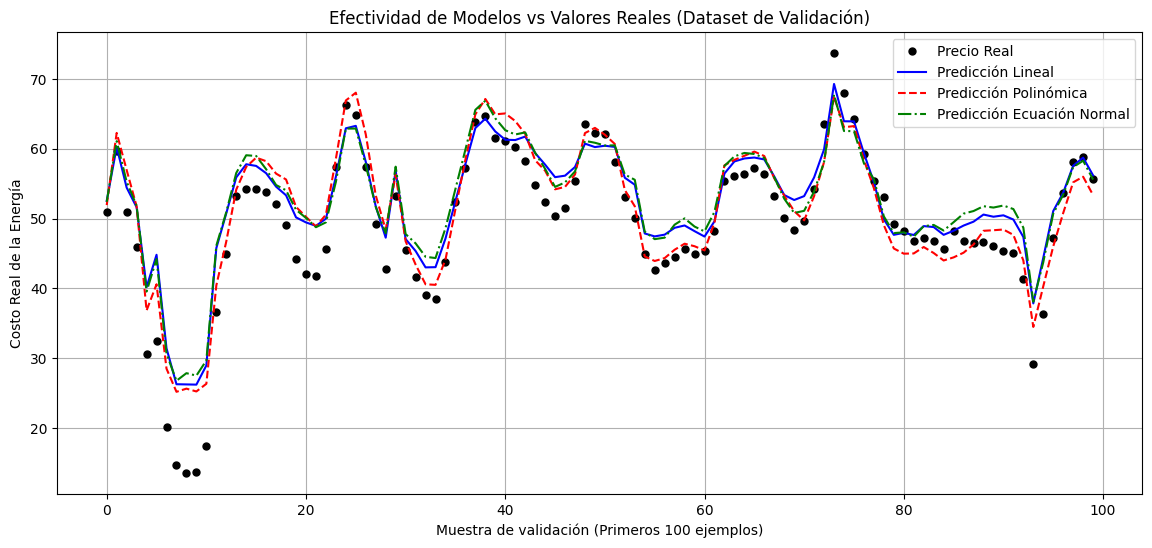

In [7]:
# 1. Preparamos los datos de prueba Lineal
X_prueba_norm = (X_prueba - mu) / sigma
X_prueba_ready = np.concatenate([np.ones((y_prueba.size, 1)), X_prueba_norm], axis=1)

# 2. Preparamos los datos de prueba Polinómica (Grado 2)
X_prueba_poly = np.concatenate([X_prueba_norm, np.square(X_prueba_norm)], axis=1)
X_prueba_poly_listo = np.concatenate([np.ones((y_prueba.size, 1)), X_prueba_poly], axis=1)

# 3. Preparamos los datos de prueba Normal (Sin normalizar)
X_prueba_norm_unos = np.concatenate([np.ones((y_prueba.size, 1)), X_prueba], axis=1)

# Generamos las predicciones con los modelos
m_mostrar = 100
pred_lin = np.dot(X_prueba_ready[:m_mostrar], theta_lin)
pred_poly = np.dot(X_prueba_poly_listo[:m_mostrar], theta_poly)
pred_norm = np.dot(X_prueba_norm_unos[:m_mostrar], theta_norm)

print(f"{'Nro':>3} | {'Real ($)':>9} | {'Lineal ($)':>11} | {'Polinóm ($)':>11} | {'Normal ($)':>11}")
print("-" * 57)
for i in range(15):
    print(f"{i+1:>3} | {y_prueba[i]:>9.2f} | {pred_lin[i]:>11.2f} | {pred_poly[i]:>11.2f} | {pred_norm[i]:>11.2f}")

# Graficación Final
pyplot.figure(figsize=(14, 6))
pyplot.plot(y_prueba[:m_mostrar], 'ko', label='Precio Real', markersize=5)
pyplot.plot(pred_lin, 'b-', label='Predicción Lineal')
pyplot.plot(pred_poly, 'r--', label='Predicción Polinómica')
pyplot.plot(pred_norm, 'g-.', label='Predicción Ecuación Normal')
pyplot.xlabel('Muestra de validación (Primeros 100 ejemplos)')
pyplot.ylabel('Costo Real de la Energía')
pyplot.title('Efectividad de Modelos vs Valores Reales (Dataset de Validación)')
pyplot.legend()
pyplot.grid(True)
pyplot.show()